# Health Machine Learning Study

Three health datasets and three machine learning tasks:

1. Heart-failure classification
2. Body-fat regression
3. Obesity clustering


## Summary and problem framing

I wanted to answer three questions:

- Who may be at higher risk after heart failure?
- Can body measurements estimate body-fat percentage?
- Can I find broad obesity patterns without using the existing labels?

| Task | Final approach | Result from my latest verified run |
|---|---|---|
| Classification | Cost-sensitive Logistic Regression, threshold 0.42 | Recall 0.579, F1 0.524, ROC-AUC 0.734 |
| Regression | Weighted Voting Regressor | MAE 3.184, RMSE 3.813, R2 0.688 |
| Clustering | K-Means with K=2 | Silhouette score about 0.245 |



## What I have done

| Requirement | What I did |
|---|---|
| EDA | Summary statistics, correlations, distributions, and class balance |
| Cleaning | Checked missing values and duplicates, corrected one typo, and removed leakage |
| Classification | Four standard models and two creative models |
| Regression | Four standard models and two creative models |
| Clustering | K-Means with K selection and a stability check |
| Tuning | Grid Search and five-fold cross-validation |
| Ensemble | Weighted Voting for classification and regression |
| Overfitting | Cross-validation, tree limits, regularization, and final test sets |
| Extra work | Feature engineering, feature selection, threshold tuning, fairness, and failed experiments |

### My workflow

```text
Question -> Load and check data -> Explore it -> Prepare features
         -> Split the data -> Train and compare -> Choose one model
         -> Test it once -> Explain results and limitations
```

Clustering has no target. I encoded and scaled the data, selected K, built the groups, and then described them.


## A. Setup

The public version of this notebook expects the three CSV files inside the repository's `data/` folder.

The first code cell imports the libraries used throughout the study.


In [46]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import (
    RandomForestClassifier, RandomForestRegressor,
    VotingClassifier, VotingRegressor,
)
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, adjusted_rand_score,
    f1_score, fbeta_score, mean_absolute_error, mean_squared_error,
    precision_score, r2_score, recall_score, roc_auc_score,
    silhouette_score,
)
from sklearn.model_selection import (
    GridSearchCV, KFold, StratifiedKFold, cross_val_predict,
    cross_val_score, train_test_split,
)
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Here I set the folder, random seed, and colors. The seed makes my split and model results repeatable.


In [47]:
SEED = 42

PROJECT_FOLDER = Path("..")
DATA_FOLDER = PROJECT_FOLDER / "data"
FIGURES_FOLDER = PROJECT_FOLDER / "figures"
FIGURES_FOLDER.mkdir(parents=True, exist_ok=True)

DARK = "#121313"
CORAL = "#FF6044"
CREAM = "#FFF4D6"

sns.set_theme(style="darkgrid")
plt.rcParams["figure.facecolor"] = DARK
plt.rcParams["axes.facecolor"] = DARK
plt.rcParams["text.color"] = CREAM
plt.rcParams["axes.labelcolor"] = CREAM
plt.rcParams["xtick.color"] = CREAM
plt.rcParams["ytick.color"] = CREAM

expected_files = [
    DATA_FOLDER / "classification_heart_failure.csv",
    DATA_FOLDER / "regression_body_fat.csv",
    DATA_FOLDER / "clustering_obesity.csv",
]

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("Files found:", {path.name: path.exists() for path in expected_files})


Python: 3.13.15
pandas: 2.2.3
scikit-learn: 1.6.1
Files found: {'classification_heart_failure.csv': True, 'regression_body_fat.csv': True, 'clustering_obesity.csv': True}


### Two small helper functions

I compare many models using the same rules. These functions stop me from copying the metric code six times.

- `classification_cv` returns accuracy, precision, recall, F1, and ROC-AUC.
- `regression_cv` returns MAE, RMSE, and R2.


In [48]:
def save_plot(filename):
    plt.tight_layout()
    plt.savefig(FIGURES_FOLDER / filename, dpi=200, bbox_inches="tight")
    plt.show()


def classification_cv(name, model, X, y, cv, threshold=0.5):
    probabilities = cross_val_predict(
        model, X, y, cv=cv, method="predict_proba", n_jobs=-1
    )[:, 1]
    predictions = (probabilities >= threshold).astype(int)

    result = {
        "Model": name,
        "Accuracy": accuracy_score(y, predictions),
        "Precision": precision_score(y, predictions, zero_division=0),
        "Recall": recall_score(y, predictions, zero_division=0),
        "F1": f1_score(y, predictions, zero_division=0),
        "ROC-AUC": cross_val_score(
            model, X, y, cv=cv, scoring="roc_auc", n_jobs=-1
        ).mean(),
    }
    return result, predictions, probabilities


def regression_cv(name, model, X, y, cv):
    predictions = cross_val_predict(model, X, y, cv=cv, n_jobs=-1)
    result = {
        "Model": name,
        "MAE": mean_absolute_error(y, predictions),
        "RMSE": np.sqrt(mean_squared_error(y, predictions)),
        "R2": r2_score(y, predictions),
    }
    return result, predictions


## B. Heart-failure classification

**My question:** Can clinical measurements help me identify patients at higher risk of death?

`DEATH_EVENT` is the target: 0 means survived and 1 means died. I leave out `time` because it contains completed follow-up information that would not be known at admission.

**Source:** [Heart Failure Clinical Records - Kaggle](https://www.kaggle.com/datasets/rabieelkharoua/predict-survival-of-patients-with-heart-failure)


### Loading and checking the classification data

I start by checking the size, missing values, duplicates, data types, and summary statistics.


In [49]:
heart = pd.read_csv(DATA_FOLDER / "classification_heart_failure.csv")

heart_quality = pd.DataFrame({
    "Missing": heart.isna().sum(),
    "Data type": heart.dtypes.astype(str),
})

print("Shape:", heart.shape)
print("Duplicate rows:", heart.duplicated().sum())
display(heart.head(), heart_quality, heart.describe().T.round(2))


Shape: (299, 13)
Duplicate rows: 0


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


,Missing,Data type
age,0,float64
anaemia,0,int64
creatinine_phosphokinase,0,int64
diabetes,0,int64
ejection_fraction,0,int64
high_blood_pressure,0,int64
platelets,0,float64
serum_creatinine,0,float64
serum_sodium,0,int64
sex,0,int64


,count,mean,std,min,25%,50%,75%,max
age,299.0,60.83,11.89,40.0,51.0,60.0,70.0,95.0
anaemia,299.0,0.43,0.50,0.0,0.0,0.0,1.0,1.0
creatinine_phosphokinase,299.0,581.84,970.29,23.0,116.5,250.0,582.0,7861.0
diabetes,299.0,0.42,0.49,0.0,0.0,0.0,1.0,1.0
ejection_fraction,299.0,38.08,11.83,14.0,30.0,38.0,45.0,80.0
high_blood_pressure,299.0,0.35,0.48,0.0,0.0,0.0,1.0,1.0
platelets,299.0,263358.03,97804.24,25100.0,212500.0,262000.0,303500.0,850000.0
serum_creatinine,299.0,1.39,1.03,0.5,0.9,1.1,1.4,9.4
serum_sodium,299.0,136.63,4.41,113.0,134.0,137.0,140.0,148.0
sex,299.0,0.65,0.48,0.0,0.0,1.0,1.0,1.0


### Exploring the classification data

The first graph checks the class balance. The heatmap shows the main correlations, and the boxplots compare important features for survivors and deaths.


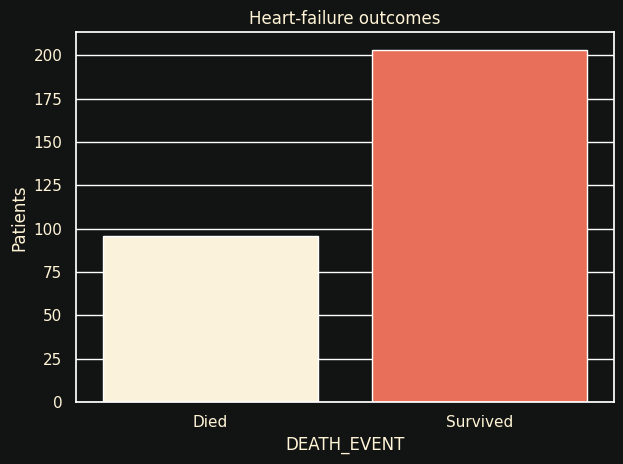

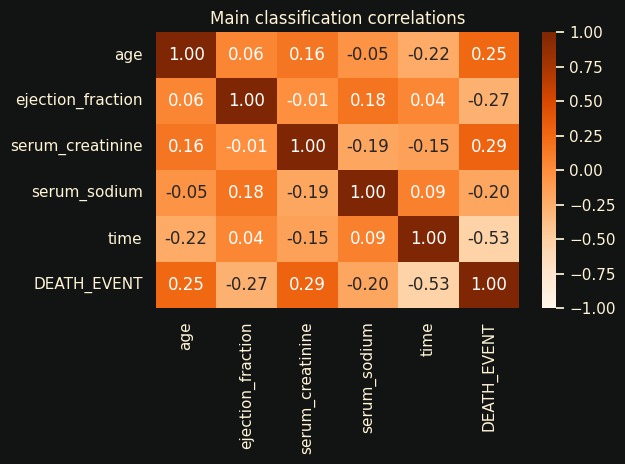

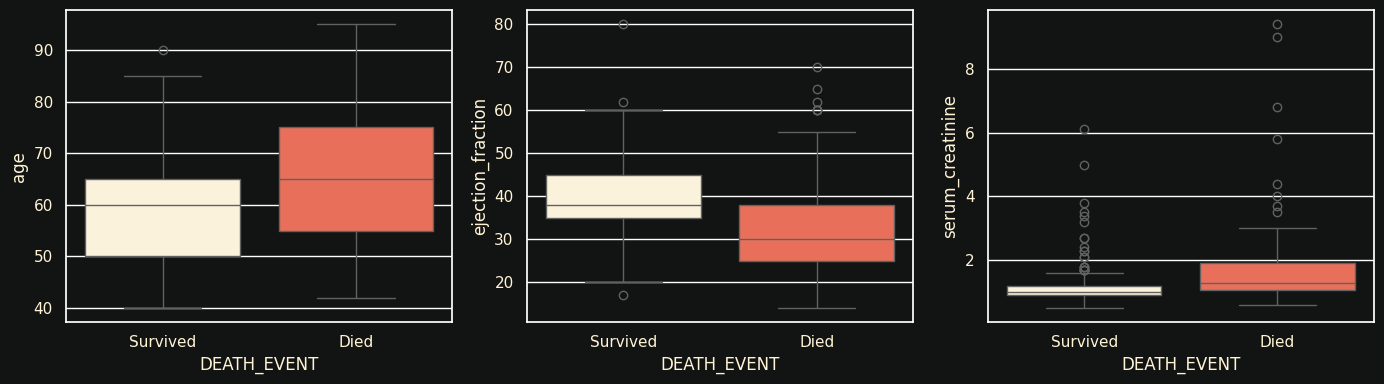

In [50]:
outcome = heart["DEATH_EVENT"].map({0: "Survived", 1: "Died"})
sns.countplot(x=outcome, hue=outcome, palette=[CREAM, CORAL], legend=False)
plt.title("Heart-failure outcomes")
plt.ylabel("Patients")
save_plot("classification_class_balance.png")

corr_columns = [
    "age", "ejection_fraction", "serum_creatinine",
    "serum_sodium", "time", "DEATH_EVENT",
]
sns.heatmap(
    heart[corr_columns].corr(), annot=True, fmt=".2f",
    cmap="Oranges", vmin=-1, vmax=1,
)
plt.title("Main classification correlations")
save_plot("classification_correlations.png")

features = ["age", "ejection_fraction", "serum_creatinine"]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for feature, ax in zip(features, axes):
    sns.boxplot(
        data=heart, x="DEATH_EVENT", y=feature,
        hue="DEATH_EVENT", palette=[CREAM, CORAL],
        legend=False, ax=ax,
    )
    ax.set_xticks([0, 1], ["Survived", "Died"])
save_plot("classification_feature_distributions.png")


### What I found in the classification data

- The dataset contains 299 patients and 13 columns.
- There are 96 deaths and 203 survivors, so the classes are not balanced.
- Deaths are generally connected with older age, lower ejection fraction, and higher serum creatinine.
- The groups overlap, so no single feature gives the full answer.
- Follow-up `time` looks useful, but using it would cause data leakage.


### Preparing the classification data

`X` contains the input features and `y` contains the answer. I keep 20% as a final test set and use five-fold cross-validation on the other 80%.


In [51]:
X = heart.drop(columns=["DEATH_EVENT", "time"])
y = heart["DEATH_EVENT"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

classification_cv_split = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=SEED
)

classification_rows = []

print("Training patients:", len(X_train))
print("Test patients:", len(X_test))
print("Features:", X_train.shape[1])


Training patients: 239
Test patients: 60
Features: 11


### Classification models

I now build the models one at a time. Each result is added to the same comparison table.


#### Dummy baseline

This model always chooses the most common answer. A real model should beat it, especially in recall for deaths.


In [52]:
dummy_classifier = DummyClassifier(strategy="most_frequent")

dummy_row, _, _ = classification_cv(
    "Dummy baseline", dummy_classifier,
    X_train, y_train, classification_cv_split,
)
classification_rows.append(dummy_row)
display(pd.DataFrame([dummy_row]).round(3))


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Dummy baseline,0.678,0.0,0.0,0.0,0.5


#### Logistic Regression

This is my first real model. Scaling puts the features on comparable ranges before Logistic Regression uses them.


In [53]:
logistic_model = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=SEED)),
])

logistic_row, _, _ = classification_cv(
    "Logistic Regression", logistic_model,
    X_train, y_train, classification_cv_split,
)
classification_rows.append(logistic_row)
display(pd.DataFrame([logistic_row]).round(3))


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.741,0.642,0.442,0.523,0.805


#### K-Nearest Neighbors

KNN looks at similar patients nearby. It needs scaling because distance is affected by the size of each feature.


In [54]:
knn_classifier = Pipeline([
    ("scale", StandardScaler()),
    ("model", KNeighborsClassifier(n_neighbors=5)),
])

knn_row, _, _ = classification_cv(
    "KNN", knn_classifier,
    X_train, y_train, classification_cv_split,
)
classification_rows.append(knn_row)
display(pd.DataFrame([knn_row]).round(3))


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,KNN,0.686,0.531,0.221,0.312,0.654


I also tried 5, 9, and 20 neighbors. This records a failed experiment instead of hiding it.


In [55]:
knn_experiment = []

for neighbors in [5, 9, 20]:
    model = Pipeline([
        ("scale", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=neighbors)),
    ])
    score = cross_val_score(
        model, X_train, y_train,
        cv=classification_cv_split, scoring="f1",
    ).mean()
    knn_experiment.append({"Neighbors": neighbors, "Mean CV F1": score})

display(pd.DataFrame(knn_experiment).round(3))


,Neighbors,Mean CV F1
0,5,0.308
1,9,0.235
2,20,0.089


#### Decision Tree

The default tree memorized the training data. Grid Search limits the tree and chooses settings with better cross-validated F1.


In [56]:
default_tree_classifier = DecisionTreeClassifier(random_state=SEED)

tree_classifier_search = GridSearchCV(
    DecisionTreeClassifier(random_state=SEED),
    {
        "max_depth": [2, 3, 4, 5, 6, None],
        "min_samples_split": [2, 5, 10, 15],
        "min_samples_leaf": [1, 3, 5, 8],
    },
    scoring="f1",
    cv=classification_cv_split,
    n_jobs=-1,
).fit(X_train, y_train)

tuned_tree_classifier = tree_classifier_search.best_estimator_
tree_row, _, _ = classification_cv(
    "Tuned Decision Tree", tuned_tree_classifier,
    X_train, y_train, classification_cv_split,
)
classification_rows.append(tree_row)

print("Best settings:", tree_classifier_search.best_params_)
display(pd.DataFrame([tree_row]).round(3))


Best settings: {'max_depth': 2, 'min_samples_leaf': 8, 'min_samples_split': 2}


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Tuned Decision Tree,0.749,0.608,0.623,0.615,0.725


In [57]:
default_tree_classifier.fit(X_train, y_train)
tuned_tree_classifier.fit(X_train, y_train)

tree_overfitting = pd.DataFrame([
    {
        "Model": "Default Tree",
        "Training accuracy": default_tree_classifier.score(X_train, y_train),
        "CV accuracy": cross_val_score(
            default_tree_classifier, X_train, y_train,
            cv=classification_cv_split, scoring="accuracy",
        ).mean(),
    },
    {
        "Model": "Tuned Tree",
        "Training accuracy": tuned_tree_classifier.score(X_train, y_train),
        "CV accuracy": cross_val_score(
            tuned_tree_classifier, X_train, y_train,
            cv=classification_cv_split, scoring="accuracy",
        ).mean(),
    },
])

display(tree_overfitting.round(3))


,Model,Training accuracy,CV accuracy
0,Default Tree,1.000,0.711
1,Tuned Tree,0.795,0.748


#### Random Forest

A Random Forest combines many trees. I tune its size and tree limits using the same training folds.


In [58]:
forest_classifier_search = GridSearchCV(
    RandomForestClassifier(random_state=SEED),
    {
        "n_estimators": [100, 200],
        "max_depth": [3, 5, 7],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf": [2, 5, 8],
        "max_features": ["sqrt", "log2"],
    },
    scoring="f1",
    cv=classification_cv_split,
    n_jobs=-1,
).fit(X_train, y_train)

tuned_forest_classifier = forest_classifier_search.best_estimator_
forest_row, _, _ = classification_cv(
    "Tuned Random Forest", tuned_forest_classifier,
    X_train, y_train, classification_cv_split,
)
classification_rows.append(forest_row)

print("Best settings:", forest_classifier_search.best_params_)
display(pd.DataFrame([forest_row]).round(3))


Best settings: {'max_depth': 3, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'min_samples_split': 2, 'n_estimators': 100}


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Tuned Random Forest,0.778,0.75,0.468,0.576,0.784


#### Creative model: Weighted Soft Voting

This model combines Logistic Regression, Decision Tree, and Random Forest probabilities. Grid Search chooses how much weight each model receives.


In [59]:
voting_classifier = VotingClassifier(
    estimators=[
        ("logistic", logistic_model),
        ("tree", tuned_tree_classifier),
        ("forest", tuned_forest_classifier),
    ],
    voting="soft",
)

voting_weight_options = [
    (1, 1, 1), (2, 1, 1), (1, 2, 1), (1, 1, 2),
    (2, 1, 2), (2, 2, 1), (1, 2, 2), (3, 1, 2),
    (2, 1, 3), (3, 1, 3),
]

voting_classifier_search = GridSearchCV(
    voting_classifier,
    {"weights": voting_weight_options},
    scoring="f1",
    cv=classification_cv_split,
    n_jobs=-1,
).fit(X_train, y_train)

weighted_voting_classifier = voting_classifier_search.best_estimator_
voting_row, _, _ = classification_cv(
    "Weighted Soft Voting", weighted_voting_classifier,
    X_train, y_train, classification_cv_split,
)
classification_rows.append(voting_row)

print("Best weights:", voting_classifier_search.best_params_["weights"])
display(pd.DataFrame([voting_row]).round(3))


Best weights: (1, 2, 2)


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Weighted Soft Voting,0.757,0.673,0.481,0.561,0.811


#### Creative model: Cost-sensitive Logistic Regression

The death class matters more here. `class_weight="balanced"` gives it more attention, and I search for a threshold that gives a strong F2 score. F2 gives recall more importance than precision.


In [60]:
cost_sensitive_classifier = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced", max_iter=1000, random_state=SEED,
    )),
])

cost_probabilities = cross_val_predict(
    cost_sensitive_classifier, X_train, y_train,
    cv=classification_cv_split,
    method="predict_proba",
    n_jobs=-1,
)[:, 1]

threshold_rows = []
for threshold in np.arange(0.10, 0.91, 0.01):
    prediction = (cost_probabilities >= threshold).astype(int)
    threshold_rows.append({
        "Threshold": threshold,
        "Precision": precision_score(y_train, prediction, zero_division=0),
        "Recall": recall_score(y_train, prediction, zero_division=0),
        "F1": f1_score(y_train, prediction, zero_division=0),
        "F2": fbeta_score(y_train, prediction, beta=2, zero_division=0),
    })

threshold_table = pd.DataFrame(threshold_rows)
best_threshold = float(
    threshold_table.sort_values(["F2", "Precision"], ascending=False)
    .iloc[0]["Threshold"]
)

cost_predictions = (cost_probabilities >= best_threshold).astype(int)
cost_row = {
    "Model": "Cost-sensitive + threshold",
    "Accuracy": accuracy_score(y_train, cost_predictions),
    "Precision": precision_score(y_train, cost_predictions, zero_division=0),
    "Recall": recall_score(y_train, cost_predictions, zero_division=0),
    "F1": f1_score(y_train, cost_predictions, zero_division=0),
    "ROC-AUC": cross_val_score(
        cost_sensitive_classifier, X_train, y_train,
        cv=classification_cv_split, scoring="roc_auc", n_jobs=-1,
    ).mean(),
}
classification_rows.append(cost_row)

print("Best threshold:", round(best_threshold, 2))
display(pd.DataFrame([cost_row]).round(3))


Best threshold: 0.42


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Cost-sensitive + threshold,0.732,0.557,0.831,0.667,0.804


### Comparing the classification models

Now the six required models appear together only for the final comparison.


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.741,0.642,0.442,0.523,0.805
1,KNN,0.686,0.531,0.221,0.312,0.654
2,Tuned Decision Tree,0.749,0.608,0.623,0.615,0.725
3,Tuned Random Forest,0.778,0.750,0.468,0.576,0.784
4,Weighted Soft Voting,0.757,0.673,0.481,0.561,0.811
5,Cost-sensitive + threshold,0.732,0.557,0.831,0.667,0.804


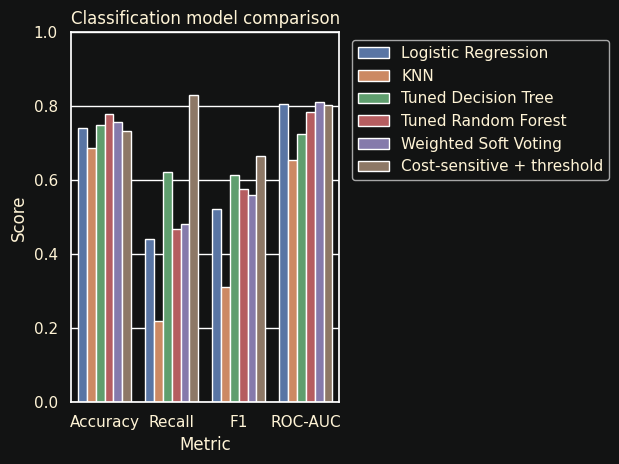

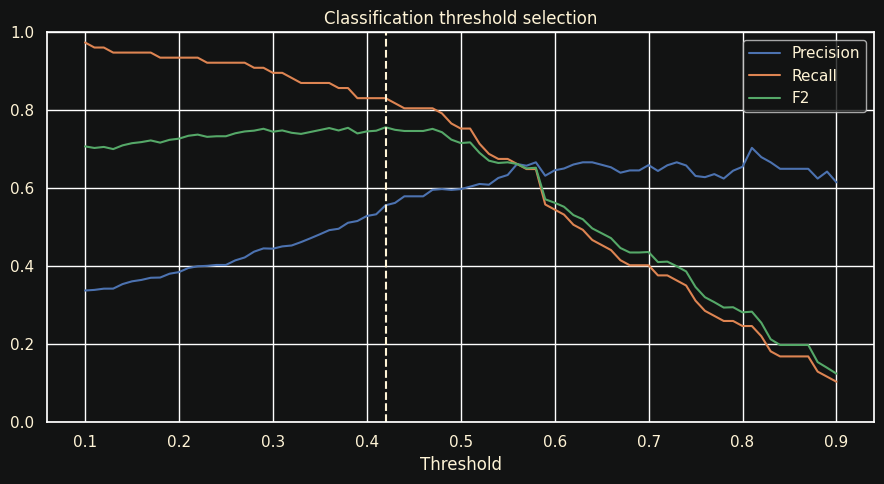

In [61]:
classification_results = (
    pd.DataFrame(classification_rows)
    .query("Model != 'Dummy baseline'")
    .reset_index(drop=True)
)
display(classification_results.round(3))

plot_data = classification_results.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Recall", "F1", "ROC-AUC"],
    var_name="Metric",
    value_name="Score",
)
sns.barplot(data=plot_data, x="Metric", y="Score", hue="Model")
plt.ylim(0, 1)
plt.title("Classification model comparison")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
save_plot("classification_model_comparison.png")

threshold_table.plot(
    x="Threshold", y=["Precision", "Recall", "F2"], figsize=(9, 5)
)
plt.axvline(best_threshold, color=CREAM, linestyle="--")
plt.ylim(0, 1)
plt.title("Classification threshold selection")
save_plot("classification_thresholds.png")


### Extra classification experiments

These experiments helped me understand the data. I kept them separate from the six main models.


#### Feature engineering

I created age squared and a creatinine-to-ejection-fraction ratio. The improvement was small.


In [62]:
X_engineered = X.copy()
X_engineered["age_squared"] = X_engineered["age"] ** 2
X_engineered["creatinine_ejection_ratio"] = (
    X_engineered["serum_creatinine"]
    / X_engineered["ejection_fraction"].clip(lower=1)
)
X_engineered_train = X_engineered.loc[X_train.index]

engineered_row, _, _ = classification_cv(
    "Logistic + engineered features", logistic_model,
    X_engineered_train, y_train, classification_cv_split,
)
display(pd.DataFrame([logistic_row, engineered_row]).round(3))


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.741,0.642,0.442,0.523,0.805
1,Logistic + engineered features,0.753,0.673,0.455,0.543,0.806


#### Feature selection

This experiment asks whether Logistic Regression can work with fewer inputs.


In [63]:
feature_selector = Pipeline([
    ("select", SelectKBest(f_classif)),
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=SEED)),
])

feature_selector_search = GridSearchCV(
    feature_selector,
    {"select__k": [3, 5, 7, 9, 11]},
    scoring="f1",
    cv=classification_cv_split,
    n_jobs=-1,
).fit(X_train, y_train)

selected_features = X_train.columns[
    feature_selector_search.best_estimator_
    .named_steps["select"].get_support()
].tolist()

print("Selected features:", selected_features)


Selected features: ['age', 'ejection_fraction', 'serum_creatinine']


#### Leakage check

Adding follow-up `time` gives a much higher score, but I reject that result because it uses future information.


In [64]:
X_with_time_train = heart.drop(columns="DEATH_EVENT").loc[X_train.index]

time_row, _, _ = classification_cv(
    "Logistic with follow-up time", logistic_model,
    X_with_time_train, y_train, classification_cv_split,
)

display(pd.DataFrame([logistic_row, engineered_row, time_row]).round(3))


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.741,0.642,0.442,0.523,0.805
1,Logistic + engineered features,0.753,0.673,0.455,0.543,0.806
2,Logistic with follow-up time,0.833,0.768,0.688,0.726,0.877


### Final classification test

I chose the recall-focused model before touching the test set. This cell now measures its final performance on 60 unseen patients.


In [65]:
cost_sensitive_classifier.fit(X_train, y_train)
test_probabilities = cost_sensitive_classifier.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= best_threshold).astype(int)

classification_test_result = pd.DataFrame([{
    "Threshold": best_threshold,
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Precision": precision_score(y_test, test_predictions, zero_division=0),
    "Recall": recall_score(y_test, test_predictions, zero_division=0),
    "F1": f1_score(y_test, test_predictions, zero_division=0),
    "F2": fbeta_score(y_test, test_predictions, beta=2, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_probabilities),
}])

display(classification_test_result.round(3))


,Threshold,Accuracy,Precision,Recall,F1,F2,ROC-AUC
0,0.42,0.667,0.478,0.579,0.524,0.556,0.734


The confusion matrix shows exactly what the model got right and wrong.


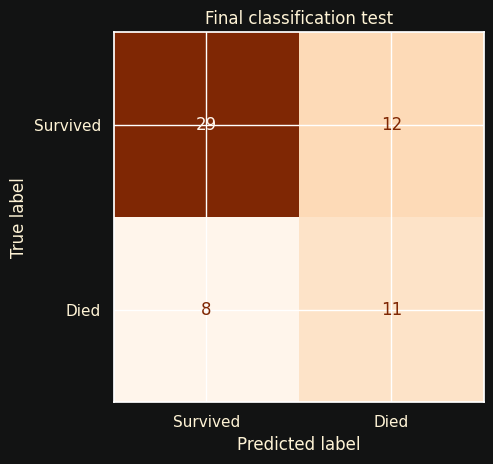

In [66]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=["Survived", "Died"],
    cmap="Oranges",
    colorbar=False,
    values_format="d",
)
plt.title("Final classification test")
save_plot("classification_final_confusion_matrix.png")


### Small fairness check

I compare women and men on the test set. The groups are small, so this is a warning check rather than proof of fairness.


In [67]:
fairness = pd.DataFrame({
    "Sex": X_test["sex"].map({0: "Women", 1: "Men"}).to_numpy(),
    "Actual": y_test.to_numpy(),
    "Predicted": test_predictions,
})

fairness_rows = []
for group, group_data in fairness.groupby("Sex"):
    fairness_rows.append({
        "Group": group,
        "Patients": len(group_data),
        "Accuracy": accuracy_score(group_data["Actual"], group_data["Predicted"]),
        "Recall": recall_score(
            group_data["Actual"], group_data["Predicted"], zero_division=0,
        ),
        "Missed deaths": (
            (group_data["Actual"] == 1)
            & (group_data["Predicted"] == 0)
        ).sum(),
    })

display(pd.DataFrame(fairness_rows).round(3))


,Group,Patients,Accuracy,Recall,Missed deaths
0,Men,41,0.634,0.583,5
1,Women,19,0.737,0.571,3


### My classification conclusion

The final test reached 66.7% accuracy, 57.9% recall, F1 of 52.4%, and ROC-AUC of 0.734. I accepted lower accuracy because this model found more deaths. The small test and fairness groups mean I would not use it for real clinical decisions without more testing.


## C. Body-fat regression

**My question:** Can body measurements estimate body-fat percentage?

`BodyFat` is a numerical target. I leave out `Density` because body-fat percentage was calculated from it, which makes it too close to the answer.

**Source:** [Body Fat Prediction Dataset - Kaggle](https://www.kaggle.com/datasets/fedesoriano/body-fat-prediction-dataset)


### Loading and checking the regression data

The original height of 29.5 inches is a documented typo, so I correct it to 69.5 inches.


In [68]:
body_fat = pd.read_csv(DATA_FOLDER / "regression_body_fat.csv")
body_fat_clean = body_fat.copy()

body_fat_clean.loc[body_fat_clean["Height"] == 29.5, "Height"] = 69.5

body_fat_quality = pd.DataFrame({
    "Missing": body_fat_clean.isna().sum(),
    "Data type": body_fat_clean.dtypes.astype(str),
})

print("Shape:", body_fat_clean.shape)
print("Duplicate rows:", body_fat_clean.duplicated().sum())
display(body_fat_clean.head(), body_fat_quality, body_fat_clean.describe().T.round(2))


Shape: (252, 15)
Duplicate rows: 0


,Density,BodyFat,Age,Weight,Height,Neck,Chest,Abdomen,Hip,Thigh,Knee,Ankle,Biceps,Forearm,Wrist
0,1.0708,12.3,23,154.25,67.75,36.2,93.1,85.2,94.5,59.0,37.3,21.9,32.0,27.4,17.1
1,1.0853,6.1,22,173.25,72.25,38.5,93.6,83.0,98.7,58.7,37.3,23.4,30.5,28.9,18.2
2,1.0414,25.3,22,154.00,66.25,34.0,95.8,87.9,99.2,59.6,38.9,24.0,28.8,25.2,16.6
3,1.0751,10.4,26,184.75,72.25,37.4,101.8,86.4,101.2,60.1,37.3,22.8,32.4,29.4,18.2
4,1.0340,28.7,24,184.25,71.25,34.4,97.3,100.0,101.9,63.2,42.2,24.0,32.2,27.7,17.7


,Missing,Data type
Density,0,float64
BodyFat,0,float64
Age,0,int64
Weight,0,float64
Height,0,float64
Neck,0,float64
Chest,0,float64
Abdomen,0,float64
Hip,0,float64
Thigh,0,float64


,count,mean,std,min,25%,50%,75%,max
Density,252.0,1.06,0.02,1.0,1.04,1.05,1.07,1.11
BodyFat,252.0,19.15,8.37,0.0,12.48,19.20,25.30,47.50
Age,252.0,44.88,12.60,22.0,35.75,43.00,54.00,81.00
Weight,252.0,178.92,29.39,118.5,159.00,176.50,197.00,363.15
Height,252.0,70.31,2.61,64.0,68.25,70.00,72.25,77.75
Neck,252.0,37.99,2.43,31.1,36.40,38.00,39.42,51.20
Chest,252.0,100.82,8.43,79.3,94.35,99.65,105.38,136.20
Abdomen,252.0,92.56,10.78,69.4,84.57,90.95,99.32,148.10
Hip,252.0,99.90,7.16,85.0,95.50,99.30,103.52,147.70
Thigh,252.0,59.41,5.25,47.2,56.00,59.00,62.35,87.30


### Exploring the regression data

I remove `Density` before checking correlations. The heatmap and histograms focus on the strongest useful body measurements.


,Correlation
Abdomen,0.813
Chest,0.703
Hip,0.625
Weight,0.612
Thigh,0.560
Knee,0.509
Biceps,0.493
Neck,0.491
Forearm,0.361
Wrist,0.347


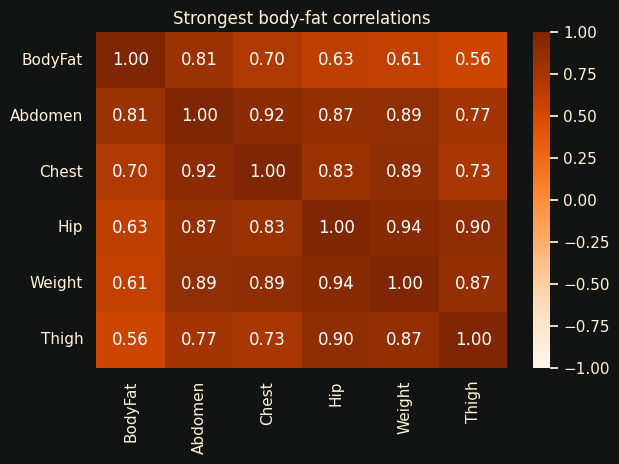

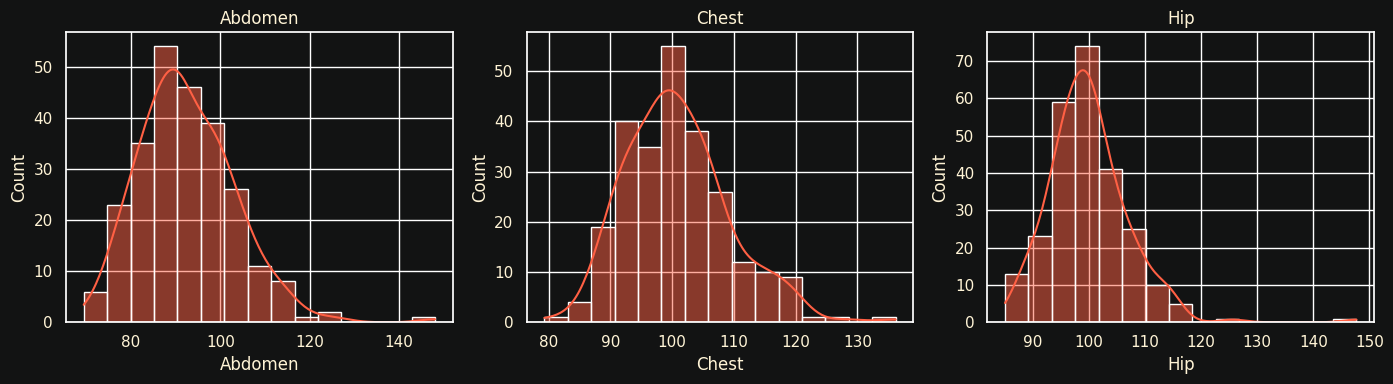

In [69]:
usable_body_fat = body_fat_clean.drop(columns="Density")
body_fat_correlations = (
    usable_body_fat.corr(numeric_only=True)["BodyFat"]
    .drop("BodyFat")
    .sort_values(key=abs, ascending=False)
)
display(body_fat_correlations.to_frame("Correlation").round(3))

top_features = body_fat_correlations.head(5).index.tolist()
sns.heatmap(
    body_fat_clean[["BodyFat"] + top_features].corr(),
    annot=True, fmt=".2f", cmap="Oranges", vmin=-1, vmax=1,
)
plt.title("Strongest body-fat correlations")
save_plot("regression_correlations.png")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for feature, ax in zip(["Abdomen", "Chest", "Hip"], axes):
    sns.histplot(body_fat_clean[feature], bins=15, kde=True, ax=ax, color=CORAL)
    ax.set_title(feature)
save_plot("regression_feature_distributions.png")


### What I found in the regression data

- The dataset contains 252 men and 15 numerical columns.
- There are no missing values or duplicate rows.
- Abdomen circumference has the strongest useful relationship with body fat.
- Many measurements are related to each other, which is why I later test Ridge.
- The data contains only men, so its fairness and generalization are limited.


### Preparing the regression data

I keep 20% for the final test and use five-fold cross-validation on the training data.


In [70]:
X_regression = body_fat_clean.drop(columns=["BodyFat", "Density"])
y_regression = body_fat_clean["BodyFat"]

X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_regression, y_regression,
    test_size=0.20,
    random_state=SEED,
)

regression_cv_split = KFold(n_splits=5, shuffle=True, random_state=SEED)
regression_rows = []

print("Training people:", len(X_reg_train))
print("Test people:", len(X_reg_test))
print("Features:", X_reg_train.shape[1])


Training people: 201
Test people: 51
Features: 13


### Regression models

For MAE and RMSE, lower is better. For R2, higher is better.


#### Dummy baseline

This predicts the training average for everyone. The useful models should make smaller errors.


In [71]:
dummy_regressor = DummyRegressor(strategy="mean")
dummy_regression_row, _ = regression_cv(
    "Dummy baseline", dummy_regressor,
    X_reg_train, y_reg_train, regression_cv_split,
)
regression_rows.append(dummy_regression_row)
display(pd.DataFrame([dummy_regression_row]).round(3))


,Model,MAE,RMSE,R2
0,Dummy baseline,7.233,8.761,-0.02


#### Linear Regression

This is the simplest real regression model and gives me a strong reference result.


In [72]:
linear_regressor = Pipeline([
    ("scale", StandardScaler()),
    ("model", LinearRegression()),
])

linear_row, _ = regression_cv(
    "Linear Regression", linear_regressor,
    X_reg_train, y_reg_train, regression_cv_split,
)
regression_rows.append(linear_row)
display(pd.DataFrame([linear_row]).round(3))


,Model,MAE,RMSE,R2
0,Linear Regression,3.804,4.593,0.72


#### Tuned KNN Regression

KNN predicts from similar people. Grid Search chooses the neighbor count and weighting method.


In [73]:
knn_regressor = Pipeline([
    ("scale", StandardScaler()),
    ("model", KNeighborsRegressor()),
])

knn_regression_search = GridSearchCV(
    knn_regressor,
    {
        "model__n_neighbors": [3, 5, 7, 9, 11, 15],
        "model__weights": ["uniform", "distance"],
    },
    scoring="neg_mean_absolute_error",
    cv=regression_cv_split,
    n_jobs=-1,
).fit(X_reg_train, y_reg_train)

tuned_knn_regressor = knn_regression_search.best_estimator_
knn_regression_row, _ = regression_cv(
    "Tuned KNN", tuned_knn_regressor,
    X_reg_train, y_reg_train, regression_cv_split,
)
regression_rows.append(knn_regression_row)

print("Best settings:", knn_regression_search.best_params_)
display(pd.DataFrame([knn_regression_row]).round(3))


Best settings: {'model__n_neighbors': 11, 'model__weights': 'distance'}


,Model,MAE,RMSE,R2
0,Tuned KNN,4.497,5.507,0.597


#### Tuned Decision Tree Regression

The default tree memorizes the training data. I limit it with Grid Search and compare training MAE with cross-validated MAE.


In [74]:
default_tree_regressor = DecisionTreeRegressor(random_state=SEED)

tree_regression_search = GridSearchCV(
    DecisionTreeRegressor(random_state=SEED),
    {
        "max_depth": [2, 3, 4, 5],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf": [2, 4, 8],
    },
    scoring="neg_mean_absolute_error",
    cv=regression_cv_split,
    n_jobs=-1,
).fit(X_reg_train, y_reg_train)

tuned_tree_regressor = tree_regression_search.best_estimator_
tree_regression_row, _ = regression_cv(
    "Tuned Decision Tree", tuned_tree_regressor,
    X_reg_train, y_reg_train, regression_cv_split,
)
regression_rows.append(tree_regression_row)

default_tree_regressor.fit(X_reg_train, y_reg_train)
tuned_tree_regressor.fit(X_reg_train, y_reg_train)

tree_check = pd.DataFrame([
    {
        "Model": "Default Tree",
        "Training MAE": mean_absolute_error(
            y_reg_train, default_tree_regressor.predict(X_reg_train),
        ),
        "CV MAE": regression_cv(
            "Default Tree", default_tree_regressor,
            X_reg_train, y_reg_train, regression_cv_split,
        )[0]["MAE"],
    },
    {
        "Model": "Tuned Tree",
        "Training MAE": mean_absolute_error(
            y_reg_train, tuned_tree_regressor.predict(X_reg_train),
        ),
        "CV MAE": tree_regression_row["MAE"],
    },
])

print("Best settings:", tree_regression_search.best_params_)
display(pd.DataFrame([tree_regression_row]).round(3), tree_check.round(3))


Best settings: {'max_depth': 2, 'min_samples_leaf': 2, 'min_samples_split': 2}


,Model,MAE,RMSE,R2
0,Tuned Decision Tree,4.499,5.552,0.59


,Model,Training MAE,CV MAE
0,Default Tree,0.000,5.698
1,Tuned Tree,4.009,4.499


#### Tuned Random Forest Regression

The forest averages many trees. Tuning reduces the gap between its training and cross-validated error.


In [75]:
default_forest_regressor = RandomForestRegressor(
    n_estimators=100, random_state=SEED, n_jobs=-1,
)

forest_regression_search = GridSearchCV(
    RandomForestRegressor(random_state=SEED, n_jobs=-1),
    {
        "n_estimators": [100, 200],
        "max_depth": [3, 5, None],
        "min_samples_leaf": [1, 2, 4],
    },
    scoring="neg_mean_absolute_error",
    cv=regression_cv_split,
    n_jobs=-1,
).fit(X_reg_train, y_reg_train)

tuned_forest_regressor = forest_regression_search.best_estimator_
forest_regression_row, _ = regression_cv(
    "Tuned Random Forest", tuned_forest_regressor,
    X_reg_train, y_reg_train, regression_cv_split,
)
regression_rows.append(forest_regression_row)

default_forest_regressor.fit(X_reg_train, y_reg_train)
tuned_forest_regressor.fit(X_reg_train, y_reg_train)

forest_check = pd.DataFrame([
    {
        "Model": "Default Forest",
        "Training MAE": mean_absolute_error(
            y_reg_train, default_forest_regressor.predict(X_reg_train),
        ),
        "CV MAE": regression_cv(
            "Default Forest", default_forest_regressor,
            X_reg_train, y_reg_train, regression_cv_split,
        )[0]["MAE"],
    },
    {
        "Model": "Tuned Forest",
        "Training MAE": mean_absolute_error(
            y_reg_train, tuned_forest_regressor.predict(X_reg_train),
        ),
        "CV MAE": forest_regression_row["MAE"],
    },
])

print("Best settings:", forest_regression_search.best_params_)
display(pd.DataFrame([forest_regression_row]).round(3), forest_check.round(3))


Best settings: {'max_depth': 5, 'min_samples_leaf': 4, 'n_estimators': 200}


,Model,MAE,RMSE,R2
0,Tuned Random Forest,4.055,4.936,0.676


,Model,Training MAE,CV MAE
0,Default Forest,1.505,4.105
1,Tuned Forest,2.551,4.055


#### Creative model: Weighted Voting Regression

This combines Linear Regression, KNN, and Random Forest. Grid Search chooses their weights.


In [76]:
voting_regressor = VotingRegressor([
    ("linear", linear_regressor),
    ("knn", tuned_knn_regressor),
    ("forest", tuned_forest_regressor),
])

voting_regression_search = GridSearchCV(
    voting_regressor,
    {"weights": [(1, 1, 1), (2, 1, 1), (3, 1, 1), (2, 1, 2), (3, 1, 2)]},
    scoring="neg_mean_absolute_error",
    cv=regression_cv_split,
    n_jobs=-1,
).fit(X_reg_train, y_reg_train)

weighted_voting_regressor = voting_regression_search.best_estimator_
voting_regression_row, _ = regression_cv(
    "Weighted Voting", weighted_voting_regressor,
    X_reg_train, y_reg_train, regression_cv_split,
)
regression_rows.append(voting_regression_row)

print("Best weights:", voting_regression_search.best_params_["weights"])
display(pd.DataFrame([voting_regression_row]).round(3))


Best weights: (3, 1, 1)


,Model,MAE,RMSE,R2
0,Weighted Voting,3.748,4.528,0.728


#### Creative model: Engineered-feature Ridge

I add BMI and abdomen-to-height ratio, then use Ridge to control strongly related features.


In [77]:
X_regression_engineered = X_regression.copy()
X_regression_engineered["BMI"] = (
    X_regression_engineered["Weight"] * 703
    / X_regression_engineered["Height"] ** 2
)
X_regression_engineered["Abdomen_Height_Ratio"] = (
    X_regression_engineered["Abdomen"]
    / (X_regression_engineered["Height"] * 2.54)
)

X_ridge_train = X_regression_engineered.loc[X_reg_train.index]

ridge_regressor = Pipeline([
    ("scale", StandardScaler()),
    ("model", Ridge()),
])

ridge_search = GridSearchCV(
    ridge_regressor,
    {"model__alpha": [0.01, 0.1, 1, 10, 100]},
    scoring="neg_mean_absolute_error",
    cv=regression_cv_split,
    n_jobs=-1,
).fit(X_ridge_train, y_reg_train)

engineered_ridge_regressor = ridge_search.best_estimator_
ridge_row, _ = regression_cv(
    "Engineered-feature Ridge", engineered_ridge_regressor,
    X_ridge_train, y_reg_train, regression_cv_split,
)
regression_rows.append(ridge_row)

print("Best alpha:", ridge_search.best_params_["model__alpha"])
display(pd.DataFrame([ridge_row]).round(3))


Best alpha: 1


,Model,MAE,RMSE,R2
0,Engineered-feature Ridge,3.771,4.566,0.723


### Comparing the regression models

The final table is sorted by MAE because lower error is better.


,Model,MAE,RMSE,R2
0,Weighted Voting,3.748,4.528,0.728
1,Engineered-feature Ridge,3.771,4.566,0.723
2,Linear Regression,3.804,4.593,0.720
3,Tuned Random Forest,4.055,4.936,0.676
4,Tuned KNN,4.497,5.507,0.597
5,Tuned Decision Tree,4.499,5.552,0.590
6,Dummy baseline,7.233,8.761,-0.020


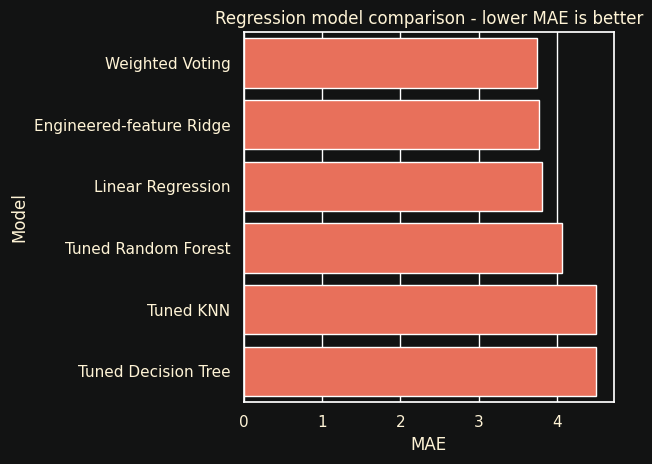

In [78]:
regression_results = (
    pd.DataFrame(regression_rows)
    .sort_values("MAE")
    .reset_index(drop=True)
)
display(regression_results.round(3))

chart_data = regression_results.query("Model != 'Dummy baseline'")
sns.barplot(data=chart_data, y="Model", x="MAE", color=CORAL)
plt.title("Regression model comparison - lower MAE is better")
save_plot("regression_model_comparison.png")


### Final regression test

Weighted Voting had the lowest cross-validated MAE, so I test it once on the 51 unseen people.


,Model,Test people,MAE,RMSE,R2
0,Weighted Voting,51,3.184,3.813,0.688


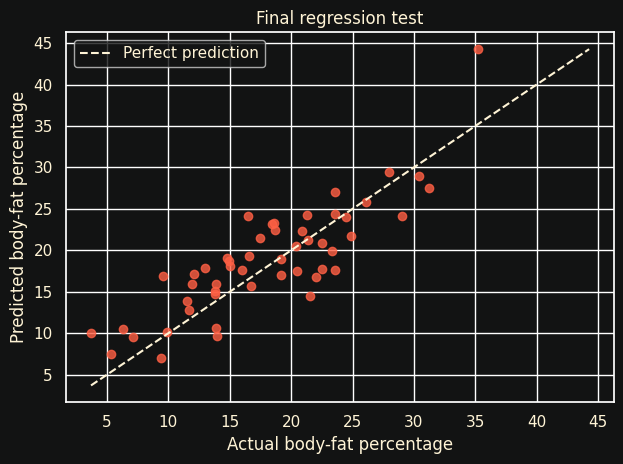

In [79]:
weighted_voting_regressor.fit(X_reg_train, y_reg_train)
regression_test_predictions = weighted_voting_regressor.predict(X_reg_test)

regression_test_result = pd.DataFrame([{
    "Model": "Weighted Voting",
    "Test people": len(y_reg_test),
    "MAE": mean_absolute_error(y_reg_test, regression_test_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_reg_test, regression_test_predictions)),
    "R2": r2_score(y_reg_test, regression_test_predictions),
}])
display(regression_test_result.round(3))

plt.scatter(y_reg_test, regression_test_predictions, color=CORAL, alpha=0.8)
low = min(y_reg_test.min(), regression_test_predictions.min())
high = max(y_reg_test.max(), regression_test_predictions.max())
plt.plot([low, high], [low, high], "--", color=CREAM, label="Perfect prediction")
plt.xlabel("Actual body-fat percentage")
plt.ylabel("Predicted body-fat percentage")
plt.title("Final regression test")
plt.legend()
save_plot("regression_final_predictions.png")


### My regression conclusion

Weighted Voting gave the lowest cross-validated MAE. On the final test, MAE was 3.184 percentage points, RMSE was 3.813, and R2 was 0.688.

The unrestricted tree overfit, and tuned KNN remained worse than Linear Regression and Voting. The dataset contains only men, so I cannot assume the same performance for women.


## D. Obesity clustering

**My question:** Can I find useful groups without using the existing obesity label?

I hide `NObeyesdad` while K-Means creates the groups. I use it only afterward to understand the result.

**Source:** [Obesity or CVD Risk Dataset - Kaggle](https://www.kaggle.com/datasets/aravindpcoder/obesity-or-cvd-risk-classifyregressorcluster)


### Loading and checking the clustering data

There are no missing values. I remove 24 duplicate rows before clustering.


In [80]:
obesity = pd.read_csv(DATA_FOLDER / "clustering_obesity.csv")
obesity_clean = obesity.drop_duplicates().reset_index(drop=True)

obesity_quality = pd.DataFrame({
    "Missing": obesity_clean.isna().sum(),
    "Data type": obesity_clean.dtypes.astype(str),
})

print("Rows before cleaning:", len(obesity))
print("Duplicate rows removed:", len(obesity) - len(obesity_clean))
print("Rows after cleaning:", len(obesity_clean))
display(obesity_clean.head(), obesity_quality, obesity_clean.describe().T.round(2))


Rows before cleaning: 2111
Duplicate rows removed: 24
Rows after cleaning: 2087


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


,Missing,Data type
Gender,0,object
Age,0,float64
Height,0,float64
Weight,0,float64
family_history_with_overweight,0,object
FAVC,0,object
FCVC,0,float64
NCP,0,float64
CAEC,0,object
SMOKE,0,object


,count,mean,std,min,25%,50%,75%,max
Age,2087.0,24.35,6.37,14.00,19.92,22.85,26.00,61.00
Height,2087.0,1.70,0.09,1.45,1.63,1.70,1.77,1.98
Weight,2087.0,86.86,26.19,39.00,66.00,83.10,108.02,173.00
FCVC,2087.0,2.42,0.53,1.00,2.00,2.40,3.00,3.00
NCP,2087.0,2.70,0.76,1.00,2.70,3.00,3.00,4.00
CH2O,2087.0,2.00,0.61,1.00,1.59,2.00,2.47,3.00
FAF,2087.0,1.01,0.85,0.00,0.12,1.00,1.68,3.00
TUE,2087.0,0.66,0.61,0.00,0.00,0.63,1.00,2.00


### Exploring the clustering data

The existing obesity categories are shown only for context. Age, height, and weight show the main numerical distributions.


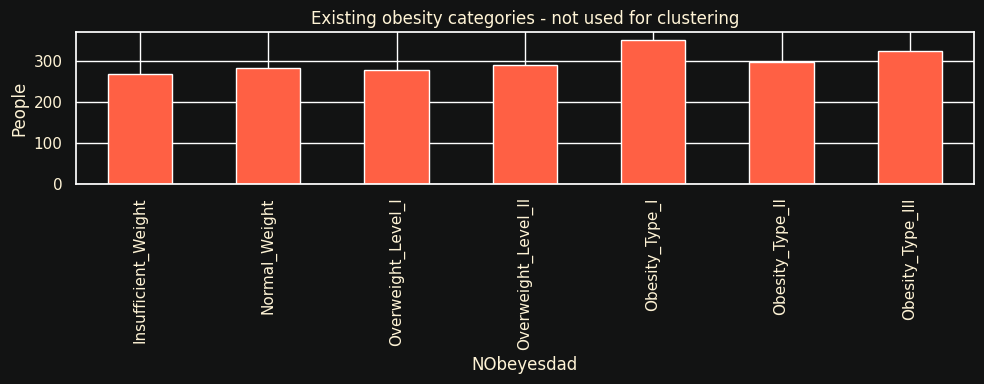

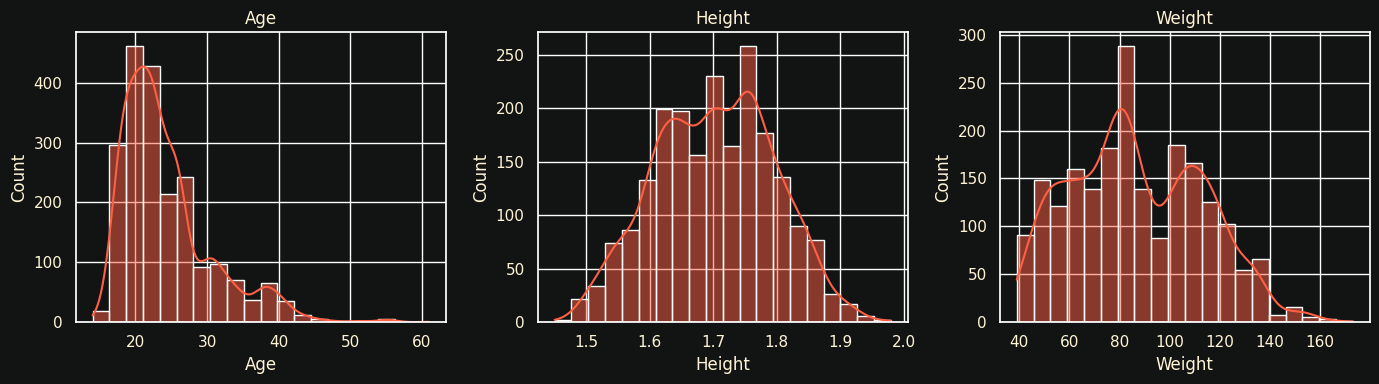

In [92]:
category_order = [
    "Insufficient_Weight", "Normal_Weight", "Overweight_Level_I",
    "Overweight_Level_II", "Obesity_Type_I", "Obesity_Type_II",
    "Obesity_Type_III",
]

obesity_clean["NObeyesdad"].value_counts().reindex(category_order).plot(
    kind="bar", color=CORAL, figsize=(10, 4)
)
plt.title("Existing obesity categories - not used for clustering")
plt.ylabel("People")
save_plot("clustering_existing_categories.png")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for feature, ax in zip(["Age", "Height", "Weight"], axes):
    sns.histplot(obesity_clean[feature], bins=20, kde=True, ax=ax, color=CORAL)
    ax.set_title(feature)
save_plot("clustering_main_distributions.png")




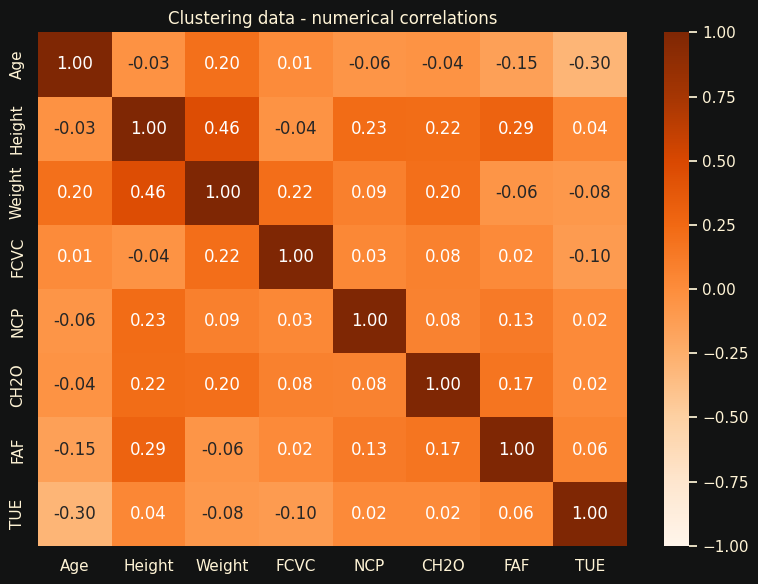

In [93]:
numeric_clustering = obesity_clean.select_dtypes(include=np.number)

plt.figure(figsize=(8, 6))
sns.heatmap(
    numeric_clustering.corr(),
    annot=True,
    fmt=".2f",
    cmap="Oranges",
    vmin=-1,
    vmax=1,
)
plt.title("Clustering data - numerical correlations")
save_plot("clustering_correlations.png")

### Preparing the clustering inputs

I remove the hidden label, turn words into 0/1 columns, and scale every feature. Scaling stops large-number features such as weight from controlling the distances.


In [82]:
X_clustering_raw = obesity_clean.drop(columns="NObeyesdad")
X_clustering_encoded = pd.get_dummies(X_clustering_raw, dtype=float)
X_clustering_scaled = StandardScaler().fit_transform(X_clustering_encoded)

print("Features before encoding:", X_clustering_raw.shape[1])
print("Features after encoding:", X_clustering_encoded.shape[1])
print("Obesity label used as input:", "NObeyesdad" in X_clustering_raw.columns)


Features before encoding: 16
Features after encoding: 31
Obesity label used as input: False


### Choosing K

K is the number of clusters. I test K from 2 to 10. Lower inertia is useful, while a higher silhouette score means clearer separation.


In [83]:
k_rows = []

for k in range(2, 11):
    model = KMeans(n_clusters=k, n_init=20, random_state=SEED)
    labels = model.fit_predict(X_clustering_scaled)
    k_rows.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette": silhouette_score(X_clustering_scaled, labels),
    })

k_results = pd.DataFrame(k_rows)
best_k = int(k_results.loc[k_results["Silhouette"].idxmax(), "K"])

display(k_results.round(3))
print("Selected K:", best_k)


,K,Inertia,Silhouette
0,2,58113.150,0.245
1,3,53897.822,0.144
2,4,49834.711,0.154
3,5,46975.319,0.124
4,6,44028.704,0.156
5,7,41877.033,0.177
6,8,39226.392,0.154
7,9,37021.706,0.162
8,10,35624.007,0.172


Selected K: 2


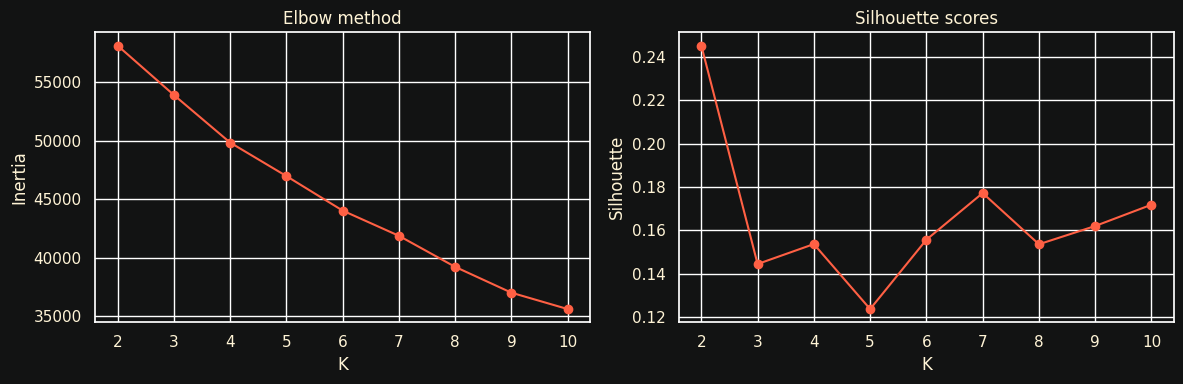

In [84]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(k_results["K"], k_results["Inertia"], marker="o", color=CORAL)
axes[0].set(title="Elbow method", xlabel="K", ylabel="Inertia")

axes[1].plot(
    k_results["K"], k_results["Silhouette"], marker="o", color=CORAL,
)
axes[1].set(title="Silhouette scores", xlabel="K", ylabel="Silhouette")

save_plot("clustering_k_selection.png")


### Building the final K-Means model

`n_init=20` means K-Means tries 20 different starting positions and keeps the best result. It does not decrease K.


In [85]:
final_kmeans = KMeans(n_clusters=best_k, n_init=20, random_state=SEED)
cluster_labels = final_kmeans.fit_predict(X_clustering_scaled)

obesity_clustered = obesity_clean.copy()
obesity_clustered["Cluster"] = cluster_labels
obesity_clustered["Cluster Name"] = obesity_clustered["Cluster"].map(
    lambda number: f"Cluster {number}"
)

print("Final number of clusters:", best_k)
print("Final silhouette:", round(
    silhouette_score(X_clustering_scaled, cluster_labels), 3,
))
display(obesity_clustered["Cluster Name"].value_counts().to_frame("People"))


Final number of clusters: 2
Final silhouette: 0.245


,People
Cluster Name,
Cluster 1,1499
Cluster 0,588


### Stability check

I repeat K-Means with a few random seeds. `Agreement with final` near 1 means the same broad grouping keeps appearing.


In [86]:
stability_rows = []

for seed in [0, 1, 2, 42, 99]:
    labels = KMeans(
        n_clusters=best_k, n_init=20, random_state=seed,
    ).fit_predict(X_clustering_scaled)

    stability_rows.append({
        "Seed": seed,
        "Silhouette": silhouette_score(X_clustering_scaled, labels),
        "Agreement with final": adjusted_rand_score(cluster_labels, labels),
    })

display(pd.DataFrame(stability_rows).round(3))


,Seed,Silhouette,Agreement with final
0,0,0.245,1.000
1,1,0.246,0.998
2,2,0.246,0.998
3,42,0.245,1.000
4,99,0.245,1.000


### Understanding the clusters

I calculate BMI only to explain the finished groups. It was not added to the K-Means inputs.


In [87]:
obesity_clustered["BMI"] = (
    obesity_clustered["Weight"] / obesity_clustered["Height"] ** 2
)

numeric_profile = obesity_clustered.groupby("Cluster Name")[[
    "Age", "Height", "Weight", "BMI", "FCVC", "NCP", "CH2O", "FAF", "TUE",
]].mean().round(2)

display(numeric_profile)


,Age,Height,Weight,BMI,FCVC,NCP,CH2O,FAF,TUE
Cluster Name,,,,,,,,,
Cluster 0,21.50,1.65,59.99,22.04,2.40,2.68,1.84,1.14,0.72
Cluster 1,25.47,1.72,97.40,32.80,2.43,2.71,2.07,0.96,0.64


In [88]:
cluster_groups = obesity_clustered.groupby("Cluster Name")

categorical_profile = pd.DataFrame({
    "People": cluster_groups.size(),
    "Women (%)": cluster_groups["Gender"].apply(
        lambda values: 100 * (values == "Female").mean()
    ),
    "Family overweight history (%)": cluster_groups[
        "family_history_with_overweight"
    ].apply(lambda values: 100 * (values == "yes").mean()),
    "High-calorie food (%)": cluster_groups["FAVC"].apply(
        lambda values: 100 * (values == "yes").mean()
    ),
    "Calorie monitoring (%)": cluster_groups["SCC"].apply(
        lambda values: 100 * (values == "yes").mean()
    ),
}).round(1)

display(categorical_profile)


,People,Women (%),Family overweight history (%),High-calorie food (%),Calorie monitoring (%)
Cluster Name,,,,,
Cluster 0,588,67.5,41.0,65.1,16.0
Cluster 1,1499,42.6,98.8,97.5,0.1


The original obesity category is used here only to check what ended up inside each cluster.


In [89]:
label_comparison = 100 * pd.crosstab(
    obesity_clustered["Cluster Name"],
    obesity_clustered["NObeyesdad"],
    normalize="index",
)

display(label_comparison.round(1))


NObeyesdad,Insufficient_Weight,Normal_Weight,Obesity_Type_I,Obesity_Type_II,Obesity_Type_III,Overweight_Level_I,Overweight_Level_II
Cluster Name,,,,,,,
Cluster 0,32.8,37.2,2.2,0.3,0.0,15.5,11.9
Cluster 1,4.9,4.2,22.5,19.7,21.6,12.3,14.7


### Visualizing the clusters

The first graph shows the two groups using age and BMI. The stacked bars show the hidden obesity labels found inside each finished cluster.


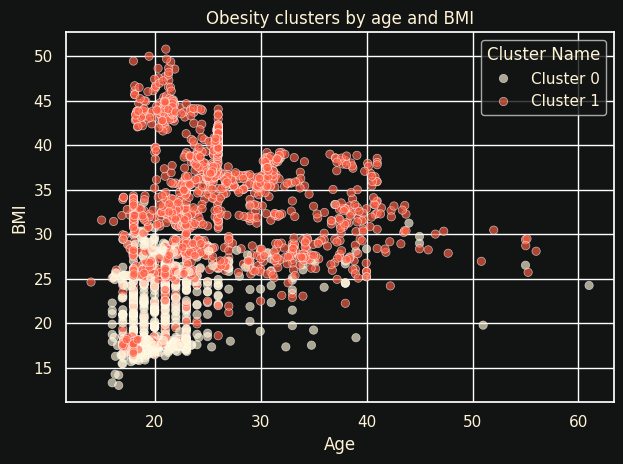

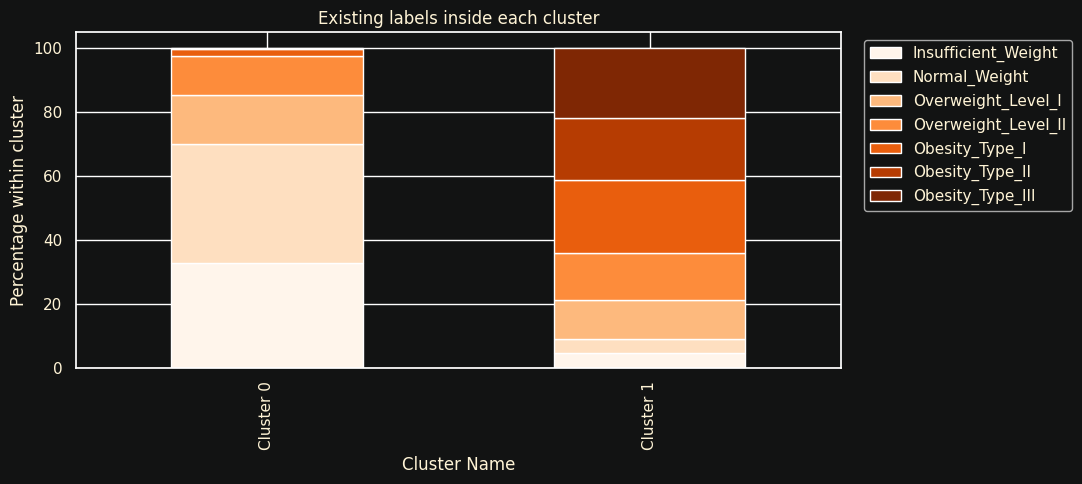

In [90]:
sns.scatterplot(
    data=obesity_clustered,
    x="Age",
    y="BMI",
    hue="Cluster Name",
    palette=[CREAM, CORAL],
    alpha=0.65,
)
plt.title("Obesity clusters by age and BMI")
save_plot("clustering_age_bmi.png")

label_comparison.reindex(columns=category_order).plot(
    kind="bar",
    stacked=True,
    figsize=(11, 5),
    colormap="Oranges",
)
plt.ylabel("Percentage within cluster")
plt.title("Existing labels inside each cluster")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
save_plot("clustering_label_comparison.png")


### My clustering conclusion

K=2 gave the highest silhouette score, about 0.245 in my latest run. One group is broadly lighter and the other is broadly heavier. The silhouette score is modest, so the groups overlap and should not be treated as medical categories.

I used 20 restarts and several seeds to check stability. I did not add voting because clustering has no supervised target.


## Overall conclusion and limits

- The recall-focused classifier found more deaths but created more false warnings.
- Weighted Voting gave the lowest body-fat error.
- K-Means found two broad obesity patterns, but they were not sharply separated.

The heart-failure test is small, the body-fat data contains only men, and the obesity data may not represent every population. I would collect larger and more diverse data before using any result in practice.

### Metric meanings

- **Precision:** Of the predicted deaths, how many were correct?
- **Recall:** Of the actual deaths, how many did I find?
- **F1:** A balance between precision and recall.
- **ROC-AUC:** How well the model ranks deaths above survivors.
- **MAE:** The average absolute regression error.
- **RMSE:** Similar to MAE, but larger mistakes count more.
- **R2:** How much target variation the model explains.
- **Silhouette:** How separate and compact the clusters are.
